# Python · no model — the test functions against their published reference values

**Idea.** Every example of this gallery is only as good as its test functions:
before fitting anything, each of the 21 functions is evaluated at points where its
value is published, and its range and shape are plotted.

**Reference.** Published optima and nominal values (Virtual Library of Simulation
Experiments, Surjanovic & Bingham).

**Tags.** class: none · topic: test functions

Every notebook of this gallery relies on the test functions of
`gallery.functions` (after the [Virtual Library of Simulation Experiments](https://www.sfu.ca/~ssurjano/)).
A typo in one of them would silently bias every result built on it, so they are
checked first, against the reference values published on the library pages
(global optima, nominal points) and against the known output ranges.

In [1]:
# Setup for running this notebook outside the repository (Colab, Binder, a lone copy):
# nothing to do in the repository itself (CI, local runs). Otherwise the repository
# (datasets of data/, helpers of tools/python/gallery.py) is cloned and the released pylibkriging installed.
import importlib
import os
import subprocess
import sys
from pathlib import Path

if not Path("tools/known_issues.csv").is_file():
    if not Path("gallery/tools/known_issues.csv").is_file():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/libKriging/gallery"], check=True)
    os.chdir("gallery")
    try:
        import pylibkriging  # noqa: F401
    except ImportError:
        r = subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "pylibkriging"],
                           capture_output=True, text=True)
        if r.returncode != 0:
            raise RuntimeError(
                f"pylibkriging could not be installed for Python {sys.version_info.major}.{sys.version_info.minor} "
                "(PyPI has wheels for CPython 3.10 to 3.12 only). On Colab: Runtime > Change runtime version > "
                "2026.07 (Python 3.12), then run again.\n" + r.stderr[-500:])
        importlib.invalidate_caches()
sys.path.insert(0, str(Path("tools/python").resolve()))  # for "import gallery" (tools/python/gallery.py)
print("working directory:", os.getcwd())

working directory: /home/runner/work/gallery/gallery


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import gallery
from gallery import TESTS, design

suite = gallery.Suite("test-functions-reference-values_no-model_python")

## Reference values

In [3]:
rows = []
for name, tf in TESTS.items():
    for x, v in tf.known:
        fx = float(tf(x)[0])
        suite.check_close(f"{name}: f({np.round(x, 4).tolist()})", fx, v, rtol=1e-4, atol=1e-4)
        rows.append((name, tf.d, np.round(x, 4).tolist(), v, fx))
pd.DataFrame(rows, columns=["function", "d", "x", "reference", "computed"])

,function,d,x,reference,computed
0,forrester,1,[0.7572],-6.020740,-6.020740e+00
1,gramacy_lee_2012,1,[0.5486],-0.869011,-8.690111e-01
2,branin,2,"[-3.1416, 12.275]",0.397887,3.978874e-01
3,branin,2,"[3.1416, 2.275]",0.397887,3.978874e-01
4,branin,2,"[9.4248, 2.475]",0.397887,3.978874e-01
5,six_hump_camel,2,"[0.0898, -0.7126]",-1.031600,-1.031628e+00
6,six_hump_camel,2,"[-0.0898, 0.7126]",-1.031600,-1.031628e+00
7,goldstein_price,2,"[0.0, -1.0]",3.000000,3.000000e+00
8,log_goldstein_price,2,"[0.5, 0.25]",-3.129126,-3.129126e+00
9,lim_polynomial,2,"[0.0, 0.0]",9.000000,9.000000e+00


## Output ranges

For the engineering functions without a closed-form optimum, the range over the
domain is compared with the one reported in the literature (loose bounds: a
random sample does not reach the extremes).

In [4]:
EXPECTED_RANGES = {  # (lower bound of min, upper bound of max) over the domain
    "otl_circuit": (2.5, 10.0),
    "piston": (0.1, 1.3),
    "borehole": (2.0, 320.0),
    "wing_weight": (120.0, 480.0),
    "currin_exp": (1.0, 14.0),
    "dette_pepelyshev": (0.0, 100.0),
}
summary = []
for name, tf in TESTS.items():
    U = design.uniform(20_000, tf.d, seed=1)
    y = tf.unit(U)
    suite.check_finite(f"{name}: finite on the domain", y)
    if name in EXPECTED_RANGES:
        lo, hi = EXPECTED_RANGES[name]
        suite.check_true(f"{name}: range within [{lo}, {hi}]", lo <= y.min() and y.max() <= hi,
                   detail=f"sampled range [{y.min():.4g}, {y.max():.4g}]")
    summary.append((name, tf.d, ",".join(tf.tags), y.min(), y.max(), y.std()))
pd.DataFrame(summary, columns=["function", "d", "tags", "min", "max", "std"])

,function,d,tags,min,max,std
0,forrester,1,1d,-6.020739,1.582689e+01,4.472956
1,gramacy_lee_2012,1,"1d,nonstationary",-0.869010,5.060420e+00,1.308336
2,branin,2,2d,0.399827,3.011365e+02,51.399613
3,six_hump_camel,2,2d,-1.031379,1.568341e+02,26.327170
4,goldstein_price,2,"2d,large-range",3.038753,1.006992e+06,124829.360811
5,log_goldstein_price,2,2d,-3.123837,2.113506e+00,1.007951
6,currin_exp,2,2d,1.210475,1.379868e+01,2.657313
7,lim_polynomial,2,"2d,polynomial",0.550175,9.553903e+00,1.648864
8,gramacy_lee_2008,2,"2d,nonstationary",-0.428347,4.274577e-01,0.077044
9,ishigami,3,3d,-10.482616,1.690415e+01,3.734373


## Designs

The designs are seeded: the same seed gives the same points (reproducibility of
every notebook), and the optimized LHS is a Latin hypercube (one point per
stratum in each dimension).

In [5]:
A, B = design.lhs(20, 3, seed=7), design.lhs(20, 3, seed=7)
suite.check_close("lhs: reproducible with a seed", A, B, rtol=0, atol=0)
strata = np.floor(A * 20).astype(int)
suite.check_true("lhs: one point per stratum", all(len(set(strata[:, j])) == 20 for j in range(3)))

True

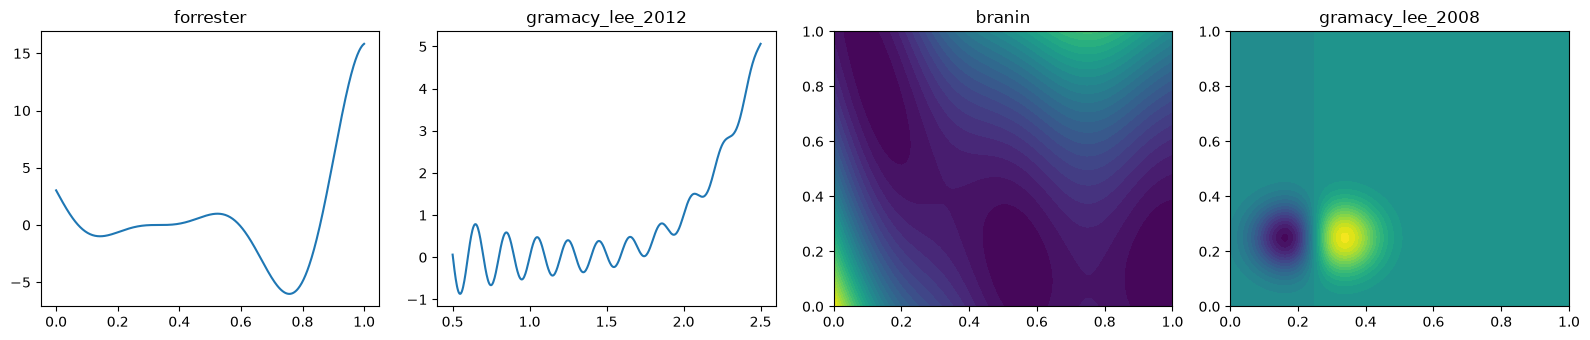

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, name in zip(axes, ["forrester", "gramacy_lee_2012"]):
    tf = TESTS[name]
    u = np.linspace(0, 1, 500)[:, None]
    ax.plot(tf.scale(u)[:, 0], tf.unit(u))
    ax.set_title(name)
for ax, name in zip(axes[2:], ["branin", "gramacy_lee_2008"]):
    tf = TESTS[name]
    g = np.linspace(0, 1, 100)
    G = np.array(np.meshgrid(g, g)).reshape(2, -1).T
    ax.contourf(g, g, tf.unit(G).reshape(100, 100), 30)
    ax.set_title(name)
plt.tight_layout()

## Summary

The metrics of this notebook, the number of checks per status, and every check that
did not pass (FAIL: error-level, fails the run; WARN: warn-level; KNOWN: listed in
`tools/known_issues.csv`, with its issue; SKIP: feature absent from the installed version).
All of them are also written to `results/test-functions-reference-values_no-model_python.checks.csv` and `.metrics.csv`.

In [7]:
suite.summary()

49 checks: PASS 49, FAIL 0, WARN 0, KNOWN 0, SKIP 0


In [8]:
suite.finalize()

test-functions-reference-values_no-model_python: PASS 49, FAIL 0, WARN 0, KNOWN 0, SKIP 0


{'PASS': 49, 'FAIL': 0, 'WARN': 0, 'KNOWN': 0, 'SKIP': 0}